In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url_data = "https://docs.google.com/spreadsheets/d/1GuFkH44urw4ACqt5gsWhi1Scei0pGS2L/export?format=csv"
df = pd.read_csv(url_data)

print("Data berhasil di-load!")
print("Jumlah baris dan kolom:", df.shape)
df.head()


Data berhasil di-load!
Jumlah baris dan kolom: (10000, 16)


,sales_date,order_id,customer_name,branch,product_name,category,color,price,quantity,payment_type,trade_in,discount,total,total_sales,status,branch_address
0,2025-12-13,TRX00001,Customer_913,Jakarta,Daihatsu Xenia 1.5 R CVT,MPV,Silver Metalik,240000000,1,Cash + Trade In,74000000,0,240000000,166000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
1,2025-10-15,TRX00002,Customer_261,Jakarta,Toyota Rush 1.5 S GR Sport CVT,SUV,Hitam Metalik,300000000,1,Kredit,0,0,300000000,300000000,completed,"Jl. MT. Haryono No. 12, Jakarta"
2,2025-01-04,TRX00003,Customer_4465,Kendari,Honda BR-V 1.5 E CVT,MPV,Merah,310000000,1,Kredit + Trade In,111000000,0,310000000,199000000,completed,"Jl. Ahmad Yani No. 33, Kendari"
3,2025-02-17,TRX00004,Customer_2788,Padang,Honda Brio Satya E CVT,Hatchback,Merah,190000000,1,Kredit,0,0,190000000,190000000,completed,"Jl. Khatib Sulaiman No. 10, Padang"
4,2025-10-02,TRX00005,Customer_2941,Karawang,Isuzu D-Max Double Cabin 4x4 AT,Pickup,Hitam Metalik,520000000,1,Cash + Trade In,93000000,0,520000000,427000000,refund,"Jl. Ahmad Yani No. 5, Karawang"


In [2]:
# 1. Tampilkan jumlah baris dan jumlah kolom dari df
df = pd.read_csv(url_data)
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (10000, 16)


In [3]:
# 2. Tampilkan nama-nama semua kolom yang ada
df = pd.read_csv(url_data)
print("Nama-nama kolom:", df.columns)

Nama-nama kolom: Index(['sales_date', 'order_id', 'customer_name', 'branch', 'product_name',
       'category', 'color', 'price', 'quantity', 'payment_type', 'trade_in',
       'discount', 'total', 'total_sales', 'status', 'branch_address'],
      dtype='object')


In [4]:
# 3. Tampilkan 10 baris pertama dari data
df = pd.read_csv(url_data)
print("10 baris pertama dari data:")
print(df.head(10))

10 baris pertama dari data:
   sales_date  order_id  customer_name     branch  \
0  2025-12-13  TRX00001   Customer_913    Jakarta   
1  2025-10-15  TRX00002   Customer_261    Jakarta   
2  2025-01-04  TRX00003  Customer_4465    Kendari   
3  2025-02-17  TRX00004  Customer_2788     Padang   
4  2025-10-02  TRX00005  Customer_2941   Karawang   
5  2025-07-05  TRX00006  Customer_3101    Bandung   
6  2025-02-21  TRX00007   Customer_570    Jakarta   
7  2025-12-16  TRX00008  Customer_2989  Pontianak   
8  2025-11-24  TRX00009  Customer_1402   Semarang   
9  2025-07-25  TRX00010  Customer_1800   Karawang   

                           product_name       category           color  \
0              Daihatsu Xenia 1.5 R CVT            MPV  Silver Metalik   
1        Toyota Rush 1.5 S GR Sport CVT            SUV   Hitam Metalik   
2                  Honda BR-V 1.5 E CVT            MPV           Merah   
3                Honda Brio Satya E CVT      Hatchback           Merah   
4       Isuzu D-Ma

In [5]:
# Hitung jumlah transaksi per kategori mobil (category), urutkan dari yang paling banyak
total_transaksi = df["category"].value_counts(ascending=False)
print("Jumlah transaksi per kategori mobil:")
print(total_transaksi)

Jumlah transaksi per kategori mobil:
category
SUV              4565
MPV              3915
Hatchback         519
Pickup            516
City Car (EV)     485
Name: count, dtype: int64


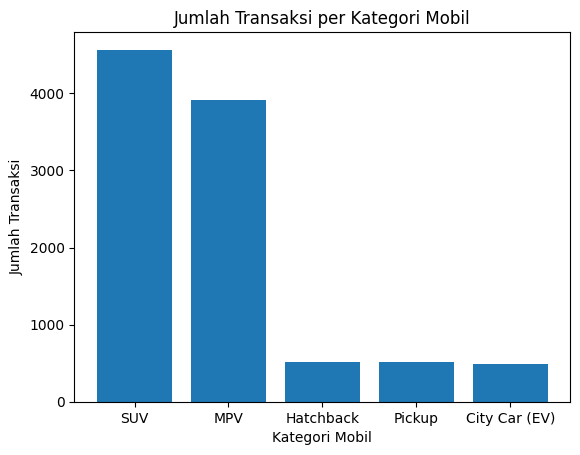

In [6]:
# (opsional) buat bar chart dari hasilnya
import matplotlib.pyplot as plt

plt.bar(total_transaksi.index, total_transaksi.values)
plt.xlabel("Kategori Mobil")
plt.ylabel("Jumlah Transaksi")
plt.title("Jumlah Transaksi per Kategori Mobil")
plt.show()

In [7]:
# Hitung jumlah transaksi per cabang (branch), urutkan dari yang paling banyak
total_transaksi = df["branch"].value_counts(ascending=False)
print("Jumlah transaksi per cabang:")
print(total_transaksi)

Jumlah transaksi per cabang:
branch
Jakarta      1058
Padang       1044
Malang       1044
Bandung       989
Batam         986
Pontianak     982
Palembang     981
Kendari       976
Karawang      973
Semarang      967
Name: count, dtype: int64


In [8]:
# lalu tampilkan cabang dengan jumlah transaksi terbanyak
print("Cabang dengan transaksi terbanyak:")
print(total_transaksi.index[0])
print("Jumlah transaksi:", total_transaksi.values[0])

Cabang dengan transaksi terbanyak:
Jakarta
Jumlah transaksi: 1058


In [9]:
# 1. Cek missing value, lalu isi trade_in yang kosong dengan 0
df["trade_in"] = df["trade_in"].fillna(0)
print("Missing value di tiap kolom:")
print(df.isnull().sum())

Missing value di tiap kolom:
sales_date        0
order_id          0
customer_name     0
branch            0
product_name      0
category          0
color             0
price             0
quantity          0
payment_type      0
trade_in          0
discount          0
total             0
total_sales       0
status            0
branch_address    0
dtype: int64


In [10]:
# 2. Cek dan hapus baris duplikat (baik duplikat penuh maupun duplikat order_id)
df = df.drop_duplicates()
df = df.drop_duplicates(subset=["order_id"])
print("Jumlah baris setelah menghapus duplikat:", df.shape[0])

Jumlah baris setelah menghapus duplikat: 10000


In [11]:
# 3. Standarisasi kolom payment_type (strip + title case)
df["payment_type"] = df["payment_type"].str.strip().str.title()
print("Standarisasi kolom payment_type:")
print(df["payment_type"].value_counts())

Standarisasi kolom payment_type:
payment_type
Kredit               4253
Cash                 2224
Kredit + Trade In    1999
Cash + Trade In      1524
Name: count, dtype: int64


In [12]:
# 4. Ubah kolom sales_date jadi tipe data datetime
df["sales_date"] = pd.to_datetime(df["sales_date"])
print("Tipe data sales_date:", df["sales_date"].dtype)

Tipe data sales_date: datetime64[ns]


In [13]:
# 5. Tampilkan df.info() untuk membuktikan data sudah lebih rapi
print("Info df setelah pembersihan:")
print(df.info())

Info df setelah pembersihan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sales_date      10000 non-null  datetime64[ns]
 1   order_id        10000 non-null  object        
 2   customer_name   10000 non-null  object        
 3   branch          10000 non-null  object        
 4   product_name    10000 non-null  object        
 5   category        10000 non-null  object        
 6   color           10000 non-null  object        
 7   price           10000 non-null  int64         
 8   quantity        10000 non-null  int64         
 9   payment_type    10000 non-null  object        
 10  trade_in        10000 non-null  int64         
 11  discount        10000 non-null  int64         
 12  total           10000 non-null  int64         
 13  total_sales     10000 non-null  int64         
 14  status          10000 non-

In [14]:
# 1. Filter transaksi yang statusnya "completed"
df_completed = df[df["status"] == "completed"]
print("Jumlah transaksi completed:", df_completed.shape[0])

Jumlah transaksi completed: 8966


In [15]:
# 2. Groupby kombinasi branch dan category, jumlahkan total_sales
grouped = df_completed.groupby(["branch", "category"])["total_sales"].sum()
print("Jumlah kombinasi branch dan category:", grouped.shape[0])

Jumlah kombinasi branch dan category: 50


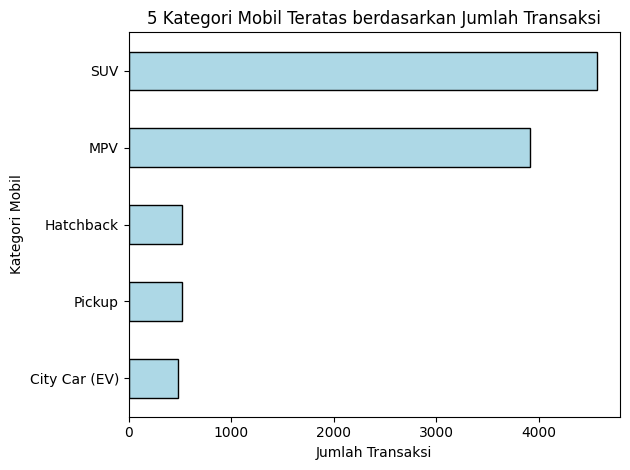

In [16]:
# 3. Urutkan dari terbesar, ambil 5 kombinasi teratas
top_5_transaski = df["category"].value_counts(ascending=False).head(5)
top_5_transaski.plot(kind="barh", color="lightblue", edgecolor="black").invert_yaxis()
plt.title("5 Kategori Mobil Teratas berdasarkan Jumlah Transaksi")
plt.xlabel("Jumlah Transaksi")
plt.ylabel("Kategori Mobil")
plt.tight_layout()
plt.show()